In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import linregress

# ==========================================
# 1. LOAD LOCAL CSV AND SPLIT DATA
# ==========================================
print("1. Loading dataset from local CSV...")
file_path = r"/content/MI.data"

# We must explicitly define all 124 columns so the paper's dictionary can find them
col_names = [
    'ID', 'AGE', 'SEX', 'INF_ANAM', 'STENOK_AN', 'FK_STENOK', 'IBS_POST', 'IBS_NASL', 'GB', 'SIM_GIPERT',
    'DLIT_AG', 'ZSN_A', 'nr_11', 'nr_01', 'nr_02', 'nr_03', 'nr_04', 'nr_07', 'nr_08', 'np_01', 'np_04',
    'np_05', 'np_07', 'np_08', 'np_09', 'np_10', 'endocr_01', 'endocr_02', 'endocr_03', 'zab_leg_01',
    'zab_leg_02', 'zab_leg_03', 'zab_leg_04', 'zab_leg_06', 'S_AD_KBRIG', 'D_AD_KBRIG', 'S_AD_ORIT',
    'D_AD_ORIT', 'O_L_POST', 'K_SH_POST', 'MP_TP_POST', 'SVT_POST', 'GT_POST', 'FIB_G_POST', 'ant_im',
    'lat_im', 'inf_im', 'post_im', 'IM_PG_P', 'ritm_ecg_p_01', 'ritm_ecg_p_02', 'ritm_ecg_p_04',
    'ritm_ecg_p_06', 'ritm_ecg_p_07', 'ritm_ecg_p_08', 'n_r_ecg_p_01', 'n_r_ecg_p_02', 'n_r_ecg_p_03',
    'n_r_ecg_p_04', 'n_r_ecg_p_05', 'n_r_ecg_p_06', 'n_r_ecg_p_08', 'n_r_ecg_p_09', 'n_r_ecg_p_10',
    'n_p_ecg_p_01', 'n_p_ecg_p_03', 'n_p_ecg_p_04', 'n_p_ecg_p_05', 'n_p_ecg_p_06', 'n_p_ecg_p_07',
    'n_p_ecg_p_08', 'n_p_ecg_p_09', 'n_p_ecg_p_10', 'n_p_ecg_p_11', 'n_p_ecg_p_12', 'fibr_ter_01',
    'fibr_ter_02', 'fibr_ter_03', 'fibr_ter_05', 'fibr_ter_06', 'fibr_ter_07', 'fibr_ter_08', 'GIPO_K',
    'K_BLOOD', 'GIPER_NA', 'NA_BLOOD', 'ALT_BLOOD', 'AST_BLOOD', 'KFK_BLOOD', 'L_BLOOD', 'ROE', 'TIME_B_S',
    'R_AB_1_n', 'R_AB_2_n', 'R_AB_3_n', 'NA_KB', 'NOT_NA_KB', 'LID_KB', 'NITR_S', 'NA_R_1_n', 'NA_R_2_n',
    'NA_R_3_n', 'NOT_NA_1_n', 'NOT_NA_2_n', 'NOT_NA_3_n', 'LID_S_n', 'B_BLOK_S_n', 'ANT_CA_S_n', 'GEPAR_S_n',
    'ASP_S_n', 'TIKL_S_n', 'TRENT_S_n',
    'FIBR_PREDS', 'PREDS_TAH', 'JELUD_TAH', 'FIBR_JELUD', 'A_V_BLOK', 'OTEK_LANC', 'RAZRIV', 'DRESSLER',
    'ZSN', 'REC_IM', 'P_IM_MAK', 'LET_IS'
]

# Load dataset and treat '?' as missing values
df = pd.read_csv(file_path, header=None, names=col_names, na_values='?')

# Split into features (skipping ID column 0) and targets (last 12 columns)
X_df_orig = df.iloc[:, 1:112].copy()
y_df_orig = df.iloc[:, 112:].copy()
target_names = list(y_df_orig.columns)


# ==========================================
# 2. DEFINE THE TEMPORAL MAPPING DICTIONARY
# ==========================================
print("2. Grouping temporal features...")
feature_collection_time = {
    'AGE': 'admission', 'SEX': 'admission', 'INF_ANAM': 'admission', 'STENOK_AN': 'admission',
    'FK_STENOK': 'admission', 'IBS_POST': 'admission', 'IBS_NASL': 'admission', 'GB': 'admission',
    'SIM_GIPERT': 'admission', 'DLIT_AG': 'admission', 'ZSN_A': 'admission', 'nr_11': 'admission',
    'nr_01': 'admission', 'nr_02': 'admission', 'nr_03': 'admission', 'nr_04': 'admission',
    'nr_07': 'admission', 'nr_08': 'admission', 'np_01': 'admission', 'np_04': 'admission',
    'np_05': 'admission', 'np_07': 'admission', 'np_08': 'admission', 'np_09': 'admission',
    'np_10': 'admission', 'endocr_01': 'admission', 'endocr_02': 'admission', 'endocr_03': 'admission',
    'zab_leg_01': 'admission', 'zab_leg_02': 'admission', 'zab_leg_03': 'admission',
    'zab_leg_04': 'admission', 'zab_leg_06': 'admission', 'S_AD_KBRIG': 'admission',
    'D_AD_KBRIG': 'admission', 'S_AD_ORIT': 'admission', 'D_AD_ORIT': 'admission',
    'O_L_POST': 'admission', 'K_SH_POST': 'admission', 'MP_TP_POST': 'admission',
    'SVT_POST': 'admission', 'GT_POST': 'admission', 'FIB_G_POST': 'admission',
    'ant_im': 'admission', 'lat_im': 'admission', 'inf_im': 'admission', 'post_im': 'admission',
    'IM_PG_P': 'admission', 'ritm_ecg_p_01': 'admission', 'ritm_ecg_p_02': 'admission',
    'ritm_ecg_p_04': 'admission', 'ritm_ecg_p_06': 'admission', 'ritm_ecg_p_07': 'admission',
    'ritm_ecg_p_08': 'admission', 'n_r_ecg_p_01': 'admission', 'n_r_ecg_p_02': 'admission',
    'n_r_ecg_p_03': 'admission', 'n_r_ecg_p_04': 'admission', 'n_r_ecg_p_05': 'admission',
    'n_r_ecg_p_06': 'admission', 'n_r_ecg_p_08': 'admission', 'n_r_ecg_p_09': 'admission',
    'n_r_ecg_p_10': 'admission', 'n_p_ecg_p_01': 'admission', 'n_p_ecg_p_03': 'admission',
    'n_p_ecg_p_04': 'admission', 'n_p_ecg_p_05': 'admission', 'n_p_ecg_p_06': 'admission',
    'n_p_ecg_p_07': 'admission', 'n_p_ecg_p_08': 'admission', 'n_p_ecg_p_09': 'admission',
    'n_p_ecg_p_10': 'admission', 'n_p_ecg_p_11': 'admission', 'n_p_ecg_p_12': 'admission',
    'fibr_ter_01': 'admission', 'fibr_ter_02': 'admission', 'fibr_ter_03': 'admission',
    'fibr_ter_05': 'admission', 'fibr_ter_06': 'admission', 'fibr_ter_07': 'admission',
    'fibr_ter_08': 'admission', 'GIPO_K': 'admission', 'K_BLOOD': 'admission',
    'GIPER_NA': 'admission', 'NA_BLOOD': 'admission', 'ALT_BLOOD': 'admission',
    'AST_BLOOD': 'admission', 'KFK_BLOOD': 'admission', 'L_BLOOD': 'admission',
    'ROE': 'admission', 'TIME_B_S': 'admission', 'NA_KB': 'admission', 'NOT_NA_KB': 'admission',
    'LID_KB': 'admission', 'NITR_S': 'admission', 'LID_S_n': 'admission',
    'B_BLOK_S_n': 'admission', 'ANT_CA_S_n': 'admission', 'GEPAR_S_n': 'admission',
    'ASP_S_n': 'admission', 'TIKL_S_n': 'admission', 'TRENT_S_n': 'admission',
    'R_AB_1_n': 'day1', 'R_AB_2_n': 'day2', 'R_AB_3_n': 'day3',
    'NA_R_1_n': 'day1', 'NA_R_2_n': 'day2', 'NA_R_3_n': 'day3',
    'NOT_NA_1_n': 'day1', 'NOT_NA_2_n': 'day2', 'NOT_NA_3_n': 'day3',
}

admission_features_names = [f for f, t in feature_collection_time.items() if t == 'admission' and f in X_df_orig.columns]
day1_features_names = [f for f, t in feature_collection_time.items() if t == 'day1' and f in X_df_orig.columns]
day2_features_names = [f for f, t in feature_collection_time.items() if t == 'day2' and f in X_df_orig.columns]
day3_features_names = [f for f, t in feature_collection_time.items() if t == 'day3' and f in X_df_orig.columns]


# ==========================================
# 3. GENERATE DERIVED TEMPORAL FEATURES
# ==========================================
print("3. Generating derived temporal features...")
temporal_base_features = ['R_AB', 'NA_R', 'NOT_NA']
derived_features = []

for base in temporal_base_features:
    day1_col, day2_col, day3_col = f'{base}_1_n', f'{base}_2_n', f'{base}_3_n'

    # Daily differences
    X_df_orig[f'{base}_diff_2_1'] = X_df_orig[day2_col] - X_df_orig[day1_col]
    X_df_orig[f'{base}_diff_3_2'] = X_df_orig[day3_col] - X_df_orig[day2_col]
    derived_features.extend([f'{base}_diff_2_1', f'{base}_diff_3_2'])

    # Mean
    X_df_orig[f'{base}_mean'] = X_df_orig[[day1_col, day2_col, day3_col]].mean(axis=1)
    derived_features.append(f'{base}_mean')

    # Trend
    def compute_trend(row):
        x, y = np.array([1, 2, 3]), row[[day1_col, day2_col, day3_col]].values
        return linregress(x, y).slope if not np.any(np.isnan(y)) else 0.0

    X_df_orig[f'{base}_trend'] = X_df_orig.apply(compute_trend, axis=1)
    derived_features.append(f'{base}_trend')

ordered_features_all = admission_features_names + day1_features_names + day2_features_names + day3_features_names + derived_features
X_df_orig = X_df_orig[ordered_features_all]


# ==========================================
# 4. IMPUTE MISSING VALUES
# ==========================================
print("4. Imputing missing values with median...")
for col in ordered_features_all:
    if X_df_orig[col].isnull().any():
        X_df_orig[col].fillna(X_df_orig[col].median(), inplace=True)


# ==========================================
# 5. PROCESS TARGET LABELS
# ==========================================
print("5. Processing target labels...")
num_binary_classes = len(target_names)
y_binary = np.zeros((y_df_orig.shape[0], num_binary_classes), dtype=int)

for col_idx, col_name in enumerate(y_df_orig.columns):
    y_df_orig[col_name].fillna(y_df_orig[col_name].median(), inplace=True)
    y_df_orig[col_name] = y_df_orig[col_name].astype(int)
    y_binary[:, col_idx] = (y_df_orig[col_name] > 0).astype(int)

# Final Arrays
X_np_all = X_df_orig.values
y_np_all = y_binary

print(f"\n✅ SUCCESS! Preprocessing complete.")
print(f"Final Features Shape (X_np_all): {X_np_all.shape}")
print(f"Final Targets Shape (y_np_all): {y_np_all.shape}")

1. Loading dataset from local CSV...
2. Grouping temporal features...
3. Generating derived temporal features...
4. Imputing missing values with median...
5. Processing target labels...

✅ SUCCESS! Preprocessing complete.
Final Features Shape (X_np_all): (1700, 123)
Final Targets Shape (y_np_all): (1700, 12)


/tmp/ipykernel_955/2978963356.py:125: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  X_df_orig[col].fillna(X_df_orig[col].median(), inplace=True)
/tmp/ipykernel_955/2978963356.py:136: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplac

In [ ]:
df_complete = pd.concat([X_df_orig, y_df_orig], axis=1)

In [ ]:
pd.DataFrame(df_complete).to_csv('full_MI_data.csv', index=False)

# EDA

In [ ]:
pd.DataFrame(X_np_all, columns=ordered_features_all).to_csv('features_MI_data.csv', index=False)

In [ ]:
df = pd.read_csv('features_MI_data.csv')
df.head()

,AGE,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,IBS_NASL,GB,SIM_GIPERT,DLIT_AG,...,R_AB_mean,R_AB_trend,NA_R_diff_2_1,NA_R_diff_3_2,NA_R_mean,NA_R_trend,NOT_NA_diff_2_1,NOT_NA_diff_3_2,NOT_NA_mean,NOT_NA_trend
0,77.0,1.0,2.0,1.0,1.0,2.0,0.0,3.0,0.0,7.0,...,0.333333,0.5,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0
1,55.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.000000,0.0,-1.0,0.0,0.333333,-0.5
2,52.0,1.0,0.0,0.0,0.0,2.0,0.0,2.0,0.0,2.0,...,1.000000,-1.5,-1.0,0.0,0.333333,-0.5,-1.0,0.0,2.333333,-0.5
3,68.0,0.0,0.0,0.0,0.0,2.0,0.0,2.0,0.0,3.0,...,0.333333,0.5,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0
4,60.0,1.0,0.0,0.0,0.0,2.0,0.0,3.0,0.0,7.0,...,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0


**Graph 1: Patient Age Distribution Segmented by Sex**

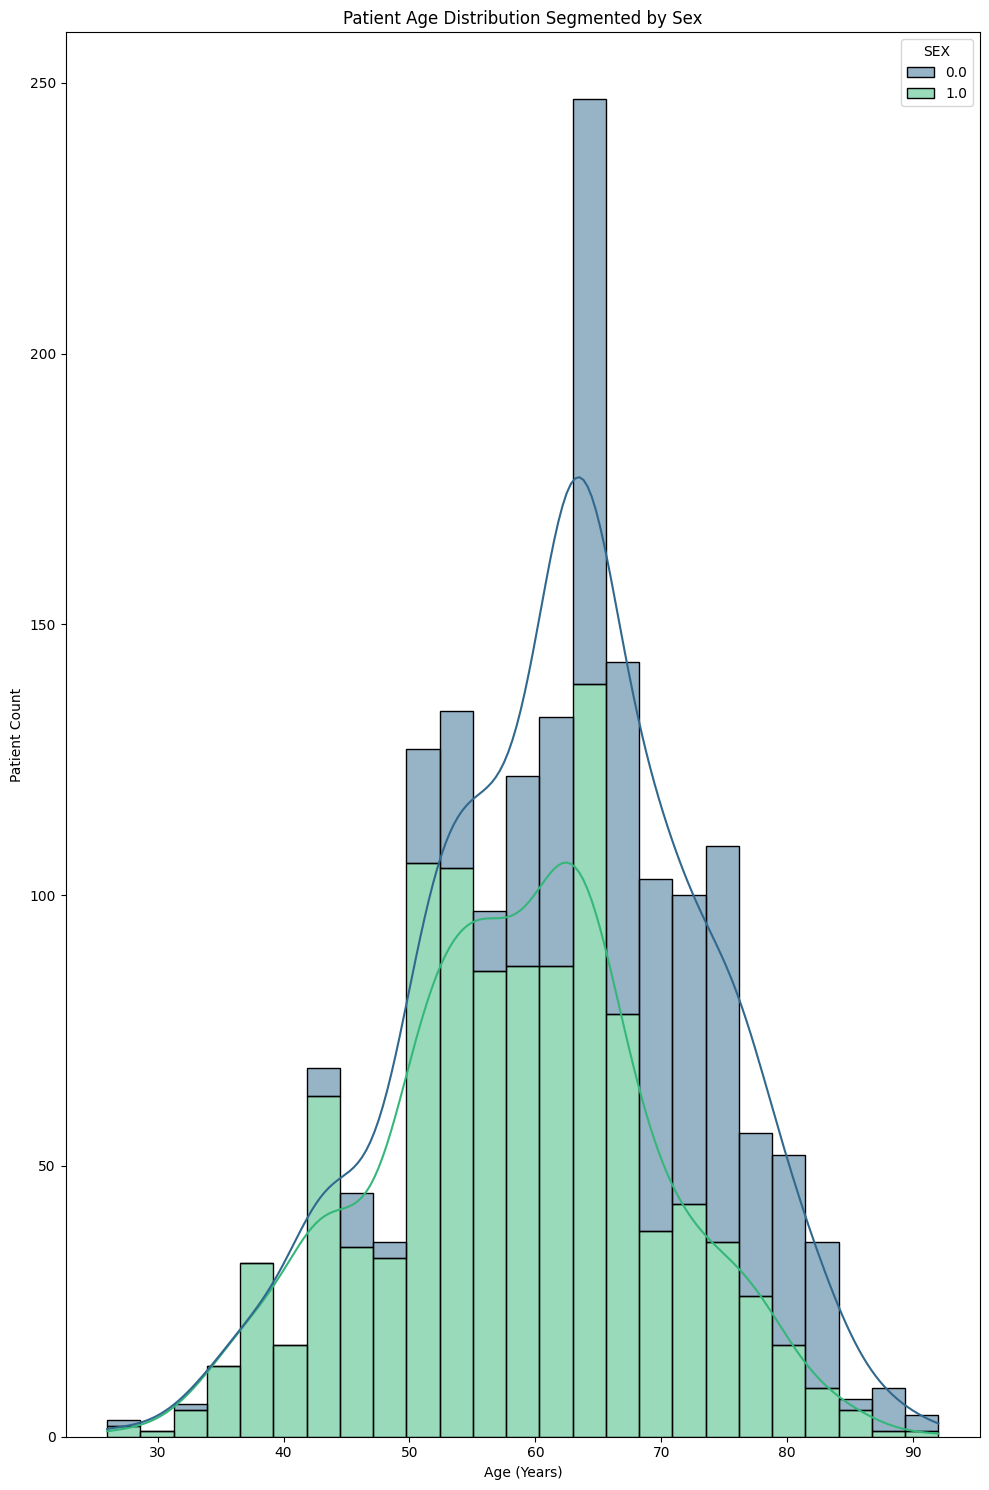

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize = (10,15))
sns.histplot(data = df, x = 'AGE', hue = 'SEX', multiple = 'stack', kde = True, palette = 'viridis')
plt.title('Patient Age Distribution Segmented by Sex')
plt.xlabel('Age (Years)')
plt.ylabel('Patient Count')
plt.tight_layout()
plt.show()

sex 0 - Men

sex 1 - Women

**Graph 2: Features to Features Correlation Heatmap**


-----Top 10 Strongest Feature Correlations-----
S_AD_ORIT        D_AD_ORIT          0.861742
D_AD_ORIT        S_AD_ORIT          0.861742
NA_R_trend       NA_R_diff_2_1      0.854912
NA_R_diff_2_1    NA_R_trend         0.854912
D_AD_KBRIG       S_AD_KBRIG         0.836794
S_AD_KBRIG       D_AD_KBRIG         0.836794
NA_R_trend       NA_R_1_n           0.836260
NA_R_1_n         NA_R_trend         0.836260
NA_R_mean        NA_R_1_n           0.826654
NA_R_1_n         NA_R_mean          0.826654
                 NA_R_diff_2_1      0.820890
NA_R_diff_2_1    NA_R_1_n           0.820890
NOT_NA_trend     NOT_NA_diff_2_1    0.819267
NOT_NA_diff_2_1  NOT_NA_trend       0.819267
NOT_NA_1_n       NOT_NA_mean        0.814779
NOT_NA_mean      NOT_NA_1_n         0.814779
NOT_NA_trend     NOT_NA_1_n         0.812649
NOT_NA_1_n       NOT_NA_trend       0.812649
R_AB_1_n         R_AB_trend         0.806549
R_AB_trend       R_AB_1_n           0.806549
dtype: float64


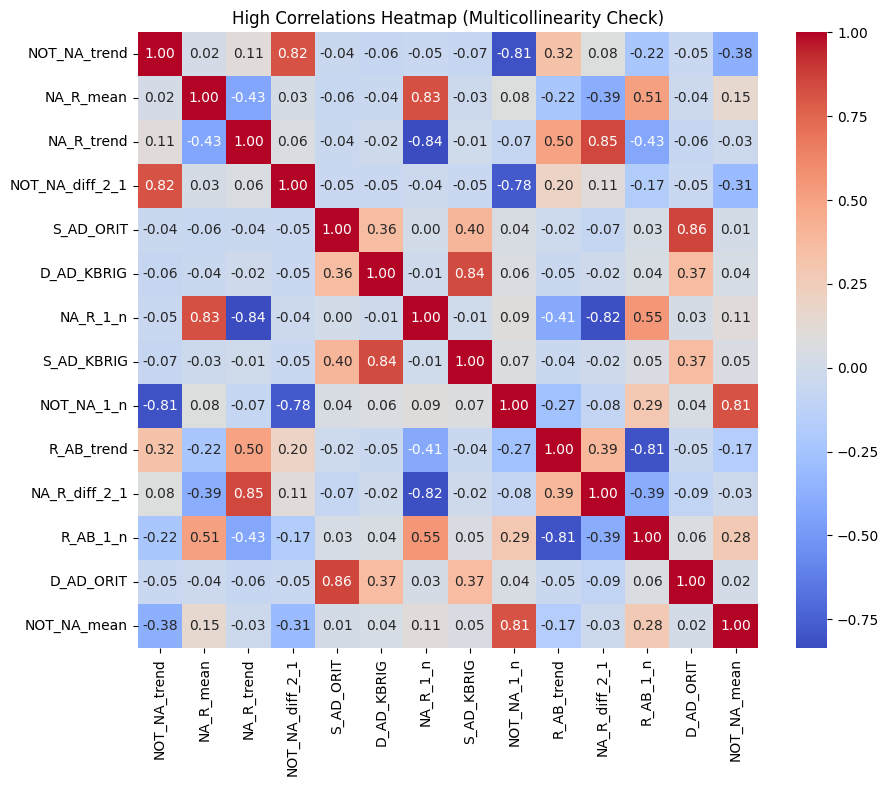

In [ ]:
print("\n-----Top 10 Strongest Feature Correlations-----")
corr_matrix = df.corr().abs()

sorted_pairs = corr_matrix.unstack().dropna().sort_values(ascending = False)
sorted_pairs = sorted_pairs[sorted_pairs < 1.0].head(20)
print(sorted_pairs.head(20))

plt.figure(figsize = (10,8))
selected_cols = list(set([index[0] for index in sorted_pairs.index]))
sns.heatmap(df[selected_cols].corr(), annot = True, cmap = 'coolwarm', fmt = ".2f")
plt.title('High Correlations Heatmap (Multicollinearity Check)')
plt.show()

**Graph 3: Lab Metric Skewness Check**


-----Checking Skewness in Blood Metrics-----


/tmp/ipykernel_955/3093156532.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data = df, x = 'SEX', y = 'AST_BLOOD', ax = ax, palette = 'muted')


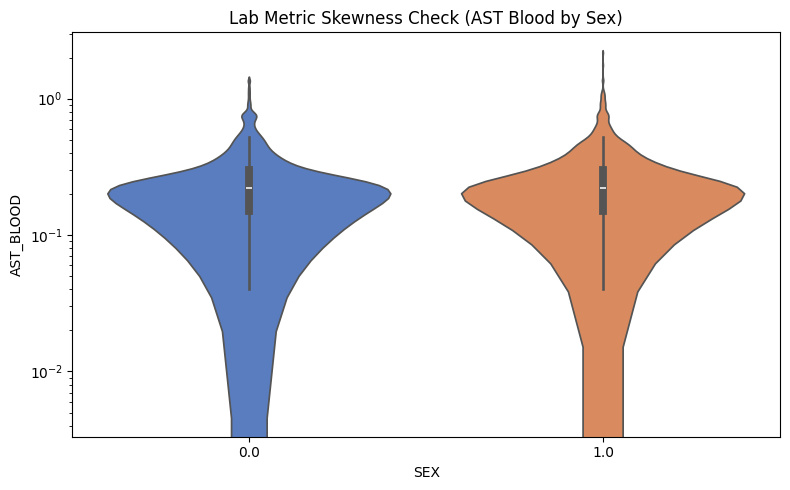

In [ ]:
fig, ax = plt.subplots(figsize = (8,5))

print("\n-----Checking Skewness in Blood Metrics-----")
sns.violinplot(data = df, x = 'SEX', y = 'AST_BLOOD', ax = ax, palette = 'muted')
ax.set_title('Lab Metric Skewness Check (AST Blood by Sex)')
ax.set_yscale('log')
plt.tight_layout()
plt.show()
plt.close()



*   In medical data, most patients have normal, low enzyme levels (the wide base), but a few patients experiencing severe myocardial infarction see their enzymes skyrocket (the thin tail).
*   AST_BLOOD levels do not structurally differ between male and female patients in this dataset.



**Graph 4: vitals Trajectory**

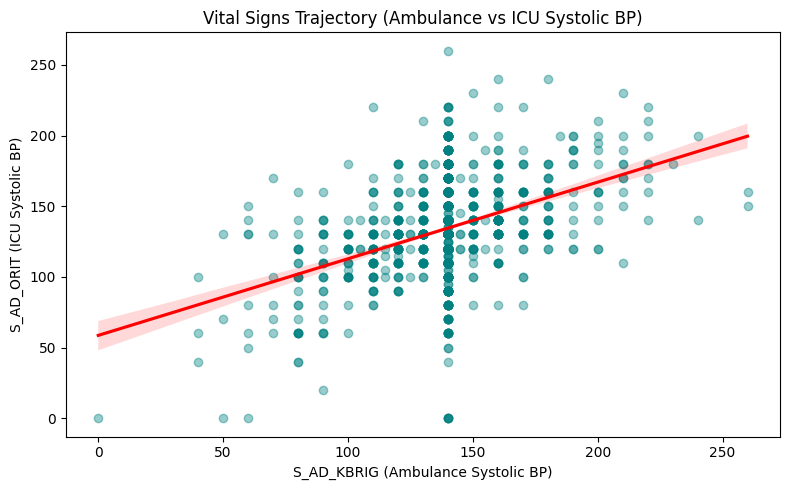

In [ ]:
fig, ax = plt.subplots(figsize = (8,5))
sns.regplot(data = df, x ='S_AD_KBRIG', y = 'S_AD_ORIT', ax = ax,
            scatter_kws = {'alpha': 0.4, 'color':'teal'}, line_kws = {'color':'red'})
ax.set_title('Vital Signs Trajectory (Ambulance vs ICU Systolic BP)')
ax.set_xlabel('S_AD_KBRIG (Ambulance Systolic BP)')
ax.set_ylabel('S_AD_ORIT (ICU Systolic BP)')
plt.tight_layout()
plt.show()
plt.close()

* The red regression line trends clearly upward from left to right
* There is a strong, direct linear correlation between a patient's blood pressure in the ambulance and their blood pressure upon arriving in the ICU. If a patient presents with extremely high blood pressure in the ambulance, they are highly likely to still have high blood pressure when they reach the hospital.
* The regression line acts as a visual average. It shows that while the two vitals are heavily linked, there is an overall stabilization or dampening effect occurring. For critically hypertensive patients (high X values), their blood pressure is significantly lower by the time they got to the ICU (lower Y values), likely due to emergency medications administered in transit.

**Graph 5: Low Variance Feature Check**

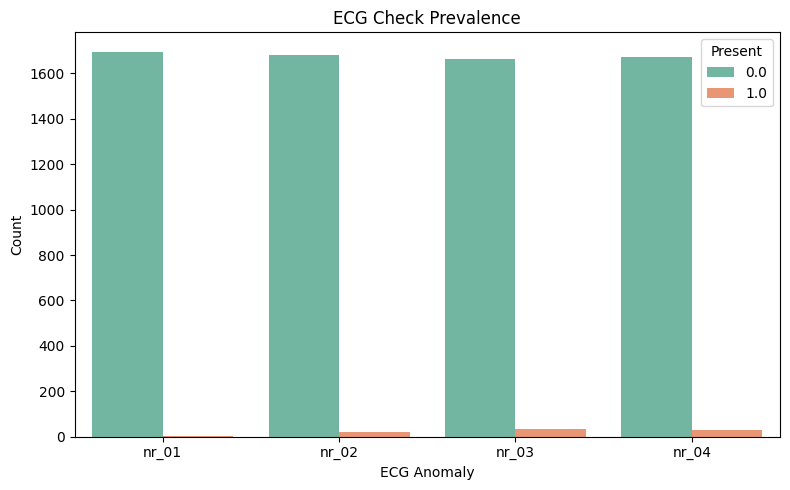

In [ ]:
fig, ax = plt.subplots(figsize = (8,5))
ecg_flags = ['nr_01', 'nr_02', 'nr_03', 'nr_04']
melted_ecg = df[ecg_flags].melt(var_name = 'ECG_Anomaly', value_name = 'Present')
sns.countplot(data = melted_ecg, x = 'ECG_Anomaly', hue = 'Present', ax = ax, palette = 'Set2')
ax.set_title('ECG Check Prevalence')
ax.set_xlabel('ECG Anomaly')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()
plt.close()



*   These specific ECG anomalies are incredibly rare in the dataset.
*   Since the variance are very low, we can treat this anomalies as one by combining themm into a single thing.



**Graph 6: Global Data Separability Check (PCA)**

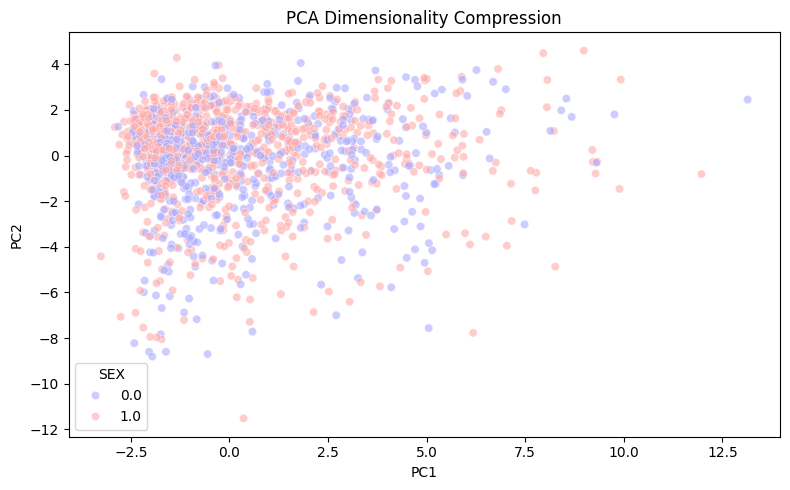

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
fig, ax = plt.subplots(figsize = (8,5))
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df.select_dtypes(include = [np.number]))

pca = PCA(n_components = 2)
pca_result = pca.fit_transform(scaled_features)
df_pca = pd.DataFrame(pca_result, columns = ['PC1', 'PC2'])
df_pca['SEX'] = df['SEX']

sns.scatterplot(data = df_pca, x = 'PC1', y = 'PC2', hue = 'SEX', alpha = 0.6,
                ax = ax, palette = 'bwr')
ax.set_title('PCA Dimensionality Compression')
plt.tight_layout()
plt.show()
plt.close()

* The data forms a cohesive, dense circular core centering around the origin (0,0), with variance spreading relatively evenly outward along both the PC1 and PC2 axes.
*  This indicates that the global variance structure of the clinical data is mostly shared across both demographic groups. Men and women in this dataset follow highly similar overall clinical patterns when all 123 variables are mathematically compressed together.

**Graph 7: Mortality Outcomes**

/tmp/ipykernel_955/99887006.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data = df, x = 'MORTALITY', ax = ax, palette = 'Set1')
/tmp/ipykernel_955/99887006.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Survived', 'Deceased'])


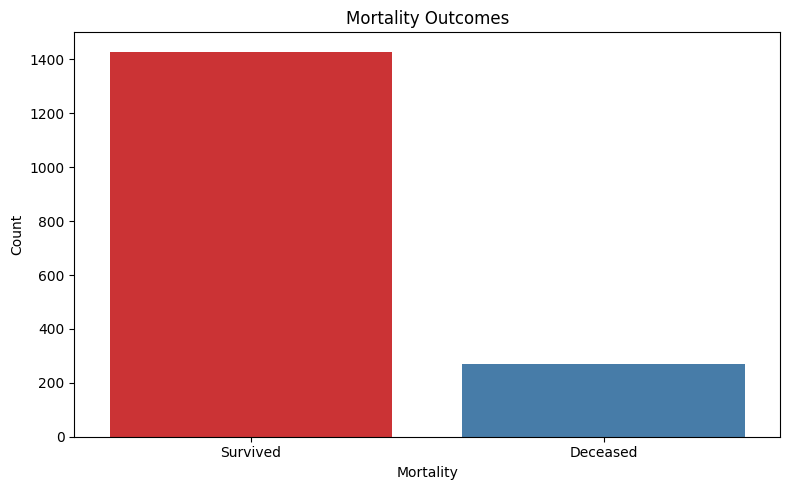

In [ ]:
df['LET_IS'] = y_df_orig['LET_IS']
df['MORTALITY'] = (df['LET_IS'] > 0).astype(int)

fig, ax = plt.subplots(figsize = (8,5))
sns.countplot(data = df, x = 'MORTALITY', ax = ax, palette = 'Set1')
ax.set_title('Mortality Outcomes')
ax.set_xticklabels(['Survived', 'Deceased'])
ax.set_xlabel('Mortality')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()
plt.close()

* The number of patients who survived is roughly 1,425, while the number of patients who are deceased stands at approximately 275 indicates that the dataset are severely imbalance.
* While a 16% mortality rate is statistically high for a patient cohort, from a data science perspective, this is a heavily skewed distribution.

**Graph 8: Enzyme Levels vs Mortality**

/tmp/ipykernel_955/4048317059.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data = df, x = 'MORTALITY', y = 'AST_BLOOD', ax = ax, palette = 'muted')
/tmp/ipykernel_955/4048317059.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Survived', 'Deceased'])


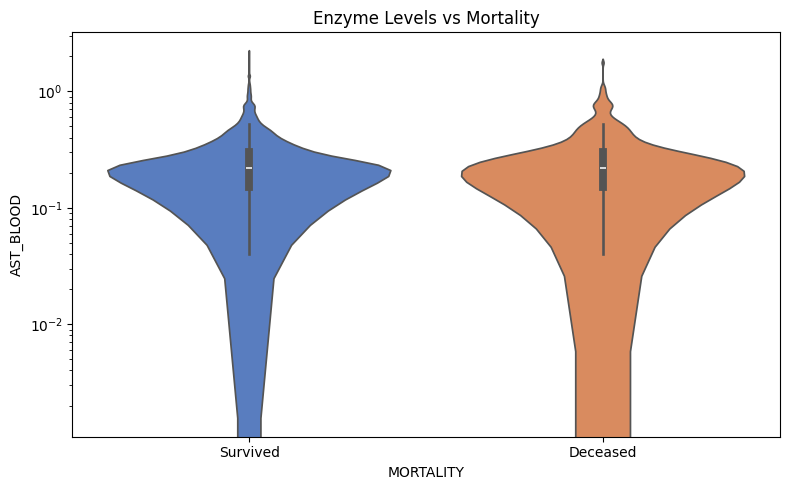

In [ ]:
fig, ax = plt.subplots(figsize = (8,5))
sns.violinplot(data = df, x = 'MORTALITY', y = 'AST_BLOOD', ax = ax, palette = 'muted')
ax.set_title('Enzyme Levels vs Mortality')
ax.set_xticklabels(['Survived', 'Deceased'])
ax.set_yscale('log')
plt.tight_layout()
plt.show()
plt.close()

* The white median dots for both 'Survived' and 'Deceased' group sit at almost the exact same horizontal plae on the Y-axis (right around 0.2). Furthermore, the internal black interquartile range (IQR) boxes share almost identical boundaries.
* Because the core distributions completely overlap, AST_BLOOD cannot be used as a standalone linear threshold to predict mortality.
* 'Survived' violin features a sall, distinct isolated secondary bulge right around the 0.7 mark, bu then sharply tapers off whereas the 'Deceased' violin has a smooth, thicker and more prominent upper neck that reaches higher tpward the maximum tip at 2.0. This show that during a myocardial infarction, a massive spike in AST enzymes indicates severe heart tissue necrosis (cell death). The plot shows that while most patients in bth categories keep baseline enzyme levels, a higehr proportion of the deceased group experiences these dangerous upper-tier enzyme spikes.

In [ ]:
df2 = pd.read_csv('full_MI_data.csv')
target_cols = ['FIBR_PREDS', 'PREDS_TAH', 'JELUD_TAH', 'FIBR_JELUD', 'A_V_BLOK', 'OTEK_LANC', 'RAZRIV', 'DRESSLER', 'ZSN', 'REC_IM', 'P_IM_MAK']
df2['MORTALITY'] = (df2['LET_IS'] > 0).astype(int)
all_targets = target_cols + ['MORTALITY']

**Graph 9: Target to Target Correlation Heatmap**

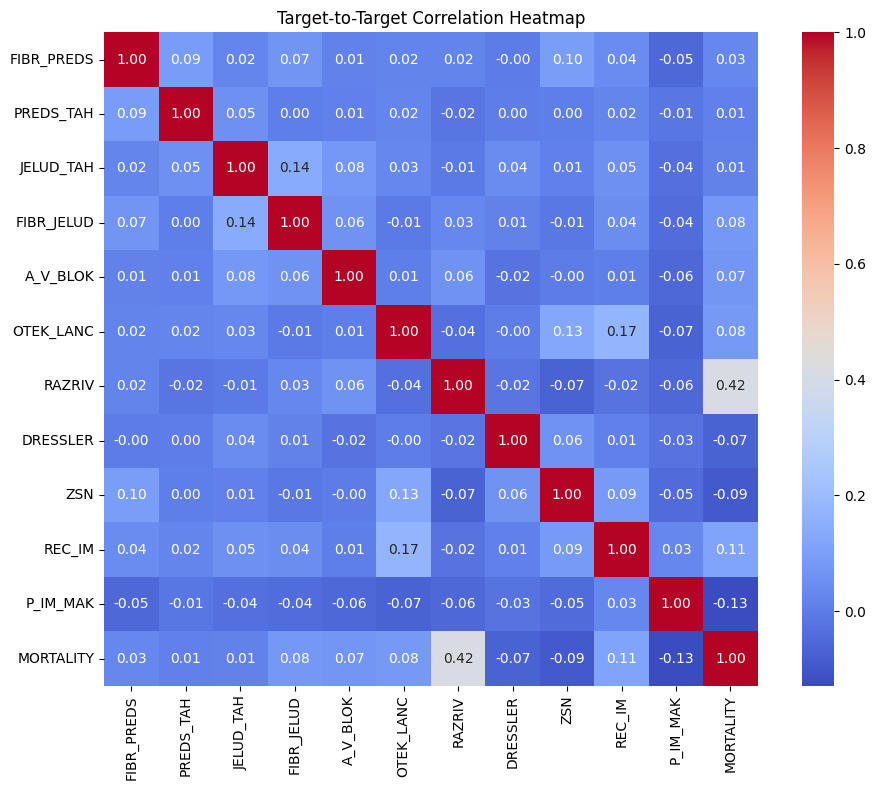

In [ ]:
plt.figure(figsize = (10,8))
corr_matrix = df2[all_targets].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True, square=True)
plt.title('Target-to-Target Correlation Heatmap')
plt.tight_layout()
plt.show()
plt.close()

* A myocardial rupture (the tearing of the heart wall) is a catastrophic structural event during a heart attack. This +0.42 value indicates that it is the strongest immediate upstream driver of lethality in this entire dataset
* There is a notable positive correlation of 0.27 between OTEK_LANC (Pulmonary Edema) and REC_IM (Recurrence of Myocardial Infarction). Patients who experience pulmonary edema (fluid buildup in the lungs due to acute heart failure) have a higher tendency to suffer a repeat heart attack (recurrence), showing a direct clinical connection between lung fluid complications and recurring isochemic events.
* Majority of the remaining cells hover between -0.05 to -0.10 indicates that the complications are mostly independent events.

**Graph 10: Prevalence of Complications and Mortality**

/tmp/ipykernel_955/2699752965.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=imbalance_df, x='Prevalence_Pct', y='Target', palette='viridis')


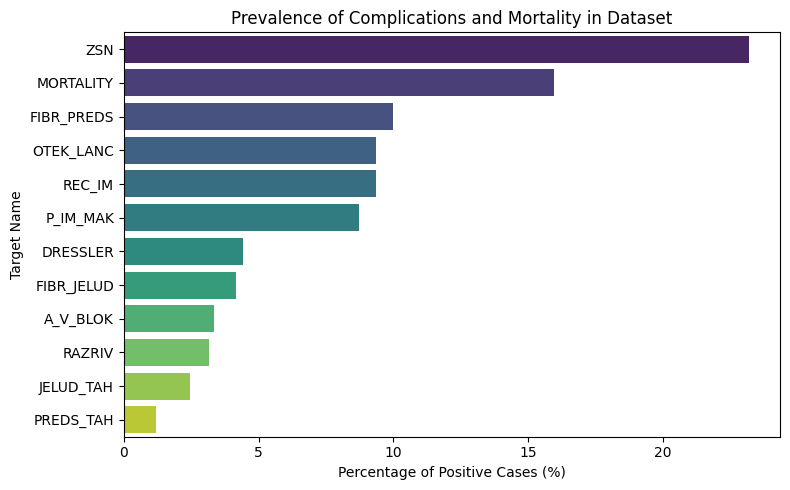

In [ ]:
plt.figure(figsize = (8,5))
imbalance_pct = (df2[all_targets].sum() / len(df2)) * 100
imbalance_df = pd.DataFrame({'Target': all_targets, 'Prevalence_Pct': imbalance_pct}).sort_values(by='Prevalence_Pct', ascending=False)

sns.barplot(data=imbalance_df, x='Prevalence_Pct', y='Target', palette='viridis')
plt.title('Prevalence of Complications and Mortality in Dataset')
plt.xlabel('Percentage of Positive Cases (%)')
plt.ylabel('Target Name')
plt.tight_layout()
plt.show()
plt.close()

* Chronic Heart Failure (ZSN) stands completely alone at the top with a prevalence of approximately 23% followed by MORTALITY and FIBR_PREDS (Atrial Fibrillation).


**Graph 11: PCA by Mortality**

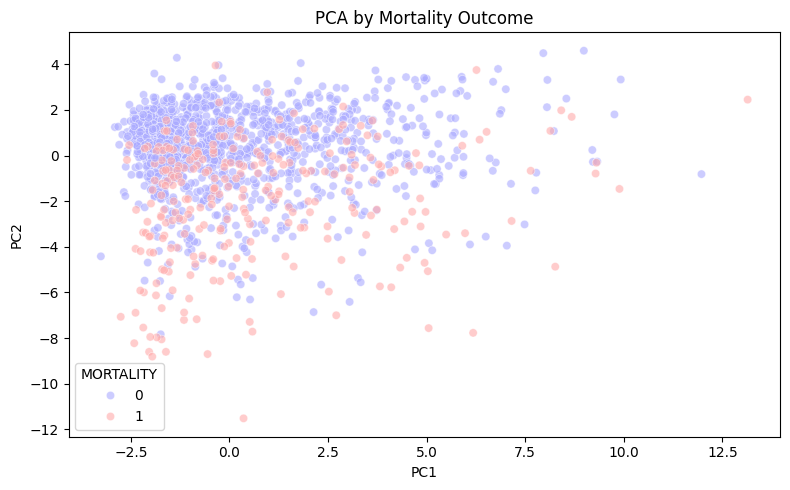

In [ ]:
plt.figure(figsize = (8,5))

feature_cols = [c for c in df2.columns if c not in all_targets and c != 'LET_IS']
X = df2[feature_cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
df_pca = pd.DataFrame(X_pca, columns = ['PC1', 'PC2'])
df_pca['MORTALITY'] = df2['MORTALITY']

sns.scatterplot(data=df_pca, x = 'PC1', y = 'PC2', hue = 'MORTALITY', alpha = 0.6, palette = 'bwr')
plt.title('PCA by Mortality Outcome')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.tight_layout()
plt.show()
plt.close()

* The vast majority of the data points are compressed into a dense, overlapping circular cloud centered roughly around (PC1: -2 to 2, PC2: -2 to 2). This core is heavily dominated by blue dots (surviving patients), though a substantial number of red dots are mixed directly inside it.
* This tells us that at admission, the vast majority of patients share almost identical clinical baselines, regardless of their eventual survival status. Their basic vitals, age metrics, and initial lab work look largely indistinguishable on a broad scale.
* Because the red and blue coordinates overlap perfectly here, a linear boundary cannot separate them, which will inevitably lead to a high rate of False Negatives (missing high-risk patients who look "normal").